# Project to EEG Sensors

Once brain activity at specific nodes have been simulated, we can project the signal to the EEG sensors to obtain simulated EEG data.

## Imports

In [74]:
import mindmap as mm
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
import mne
import seaborn as sns

## Data

In [75]:
sub = "sub-001"
mm.io.read_config("../configurations/vep.yml", env=True)

# data
data   = mm.io.read_dataset(sub, "sim", "fwd", "eeg_tmp", "ez")
labels = np.array(data["sim"].labels)

# parameters
thresh     = 1.5      # minimum spike height
win_radius = 10       # window radius (will define buffer as well)
warmup     = 50       # warmup time of simulation
n_max      = 5        # maximum number of active regions


# fix orientation of forward matrix 
fwd = data["fwd"].copy()
fwd = mne.convert_forward_solution(
    fwd,
    surf_ori=True,
    force_fixed=True,
    use_cps=True,
    verbose="warning",
)

fwd  = fwd["sol"]["data"].astype("float64")

In [76]:
def compute_snr_distribution(spikes):
    snr, snr_ez             = [], []
    n_dipoles, n_dipoles_ez = [], []
    n_regions, n_regions_ez = [], []

    times = np.unique(spikes[0])
    t_max = data["sim"].data.shape[-1]

    for t in times:
        if (t > warmup+win_radius) & (t < t_max-win_radius):
            brain_activity  = data["sim"].data[:, t-win_radius:t+win_radius]
            spiking_dipoles = spikes[1][(spikes[0]>=t-win_radius) & (spikes[0]<t+win_radius)]
            spiking_regions = np.unique(labels[spiking_dipoles])
        
            mask = np.zeros(brain_activity.shape[0], dtype=bool)
            mask[spiking_dipoles] = True

            eeg_signal     = fwd[:, mask] @ brain_activity[mask, :]
            eeg_background = fwd[:, ~mask] @ brain_activity[~mask, :]

            Ps = np.sum((eeg_signal-eeg_signal.mean(axis=1).reshape(-1,1))**2)/eeg_signal.shape[-1]
            Pb = np.sum((eeg_background-eeg_background.mean(axis=1).reshape(-1,1))**2)/eeg_background.shape[-1]

            snr.append(10*np.log10(Ps/Pb))
            n_dipoles.append(len(spiking_dipoles))
            n_regions.append(len(spiking_regions))

            if set(spiking_regions) == set(data["ez"]):
                snr_ez.append(snr[-1])
                n_dipoles_ez.append(n_dipoles[-1])
                n_regions_ez.append(n_regions[-1])

    return snr, n_dipoles, n_regions, snr_ez, n_dipoles_ez, n_regions_ez

## Fix Signal to Background Ratio

1. Find spikes
2. Iterate through spikes
    - Select data around spike (`win_radius`)
    - Skip section if more than `n_max` regions have spikes in the section (`labels` + `n_max`)
    - compute the SNR (`fwd` + `labels`) 

#### SNR distribution of all spikes

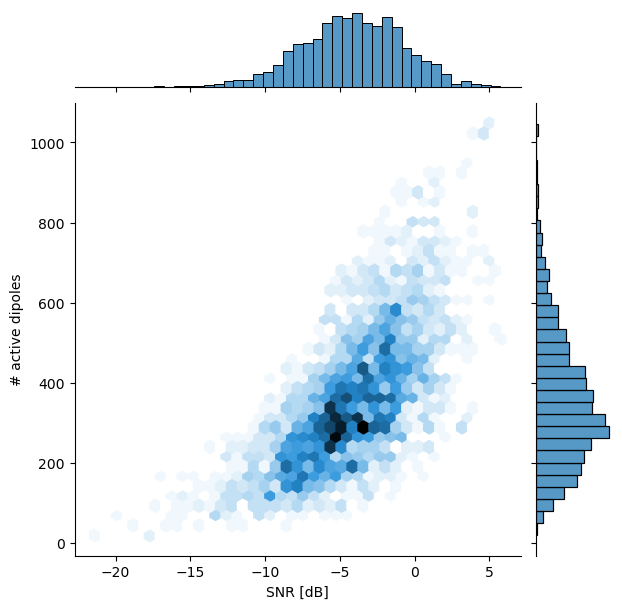

In [16]:
# find spikes
spikes = []
for i, time_serie in enumerate(data["sim"].data):
    times = sp.signal.find_peaks(time_serie, height=thresh)[0]
    spikes.append([times, [i]*len(times)])

# sort spikes
spikes     = np.hstack(spikes)    # shape = (2, n_spikes), spikes[0] -> spike times (index), spikes[1] -> region id
sorted_idx = np.argsort(spikes[0])
spikes = spikes[:,sorted_idx]

# Compute snr distribution
snr, n_dipoles, n_regions, snr_ez, n_dipoles_ez, n_regions_ez = compute_snr_distribution(spikes)

# plot
sns.jointplot(x=snr, y=n_dipoles, kind="hex")
plt.xlabel("SNR [dB]")
plt.ylabel("# active dipoles")
plt.show()

-3.1020882289946496

#### Fix SNR of Interictal Spikes
1. Isolate only interictal spikes
2. Compute SNR for only these spikes
3. Find $\alpha$ such that these SNR are like you want them
4. Apply $\sqrt{\alpha}$ to all spikes

In [ ]:
# Compute signal to background log ratio (~SNR) around each spike
snr   = []
n_dipoles = []
n_regions = []
times = np.unique(spikes[0])
t_max = data["sim"].data.shape[-1]
for t in times:
    if (t > warmup+win_radius) & (t < t_max-win_radius):
        brain_activity  = data["sim"].data[:, t-win_radius:t+win_radius]
        spiking_dipoles = spikes[1][(spikes[0]>=t-win_radius) & (spikes[0]<t+win_radius)]
        spiking_regions = np.unique(labels[spiking_dipoles])
        
        mask = np.zeros(brain_activity.shape[0], dtype=bool)
        mask[spiking_dipoles] = True

        eeg_signal     = fwd[:, mask] @ brain_activity[mask, :]
        eeg_background = fwd[:, ~mask] @ brain_activity[~mask, :]

        Ps = np.sum((eeg_signal-eeg_signal.mean(axis=1).reshape(-1,1))**2)/eeg_signal.shape[-1]
        Pb = np.sum((eeg_background-eeg_background.mean(axis=1).reshape(-1,1))**2)/eeg_background.shape[-1]

        snr.append(10*np.log10(Ps/Pb))
        n_dipoles.append(len(spiking_dipoles))
        n_regions.append(len(spiking_regions))

## Apply Forward

In [82]:
test = mne.apply_forward_raw(data["fwd"], data["sim"], data["eeg_tmp"].info, verbose="warning")

/tmp/ipykernel_3216/1957297354.py:1: RuntimeWarning: The maximum current magnitude is 3877509657.4 nAm, which is very large. Are you trying to apply the forward model to noise-normalized (dSPM, sLORETA, or eLORETA) values? The result will only be correct if currents (in units of Am) are used.
  test = mne.apply_forward_raw(data["fwd"], data["sim"], data["eeg_tmp"].info, verbose="warning")


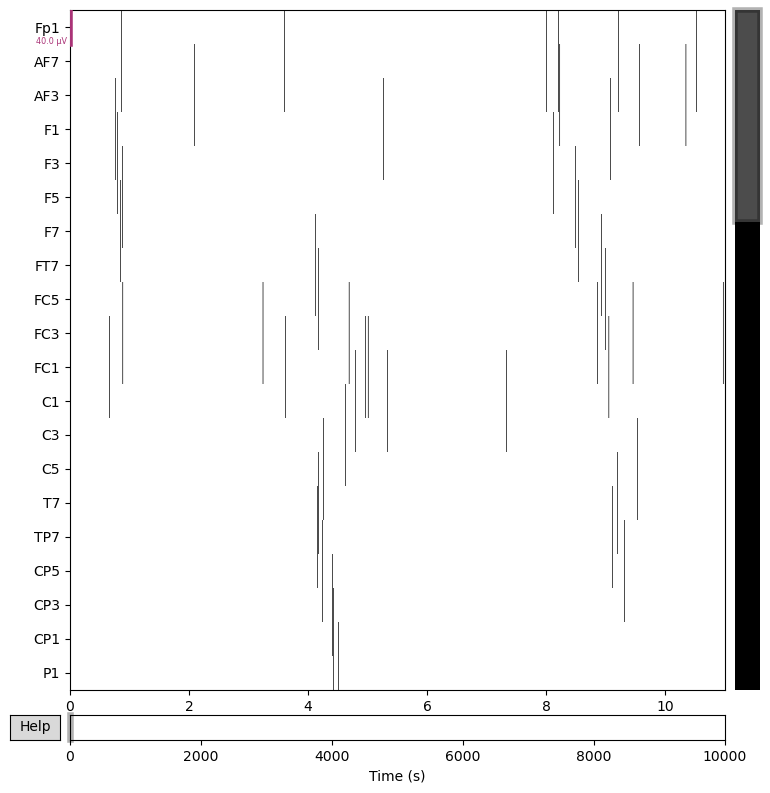

Channels marked as bad:
none


In [91]:
%matplotlib qt 
test.plot(duration=10)

In [62]:
sub = "sub-001"
mm.io.read_config("../configurations/vep.yml", env=True)

# data
data   = mm.io.read_dataset(sub, "sim_tvb", "ez", "atlas")
labels = data["atlas"]["region_name"].values[1:]

# parameters
thresh     = 1.5      # minimum spike height
win_radius = 10       # window radius (will define buffer as well)
warmup     = 50       # warmup time of simulation
n_max      = 5        # maximum number of active regions

In [64]:
# find spikes
spikes = []
for i, time_serie in enumerate(data["sim_tvb"]["source_signal"].T):
    times = sp.signal.find_peaks(time_serie, height=thresh)[0]
    spikes.append([times, [i]*len(times)])

# sort spikes
spikes     = np.hstack(spikes)    # shape = (2, n_spikes), spikes[0] -> spike times (index), spikes[1] -> region id
sorted_idx = np.argsort(spikes[0])
spikes = spikes[:,sorted_idx]

times = np.unique(spikes[0])
t_max = data["sim_tvb"]["source_signal"].T.shape[-1]

regions = []
regions_ez = []

for t in times:
    if (t > warmup+win_radius) & (t < t_max-win_radius):
        brain_activity  = data["sim_tvb"]["source_signal"].T[:, t-win_radius:t+win_radius]
        spiking_dipoles = spikes[1][(spikes[0]>=t-win_radius) & (spikes[0]<t+win_radius)]
        spiking_regions = np.unique(labels[spiking_dipoles])
        regions.append(spiking_regions)

        if set(spiking_regions) == set(data["ez"]):
            regions_ez.append(regions[-1])

In [72]:
for r in regions:
    if len(set(r).intersection(set(["Right-Hippocampus-anterior"]))) > 0:
        print(r)

['Right-Hippocampus-anterior' 'Right-Occipito-temporal-sulcus']
['Left-Hippocampus-anterior' 'Right-Hippocampus-anterior'
 'Right-Occipito-temporal-sulcus' 'Right-STS-anterior']
['Left-Hippocampus-anterior' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior' 'Right-STS-anterior']
['Right-Hippocampus-anterior' 'Right-Hippocampus-posterior'
 'Right-Insula-gyri-brevi']
['Left-Hippocampus-anterior' 'Right-Hippocampus-anterior'
 'Right-Insula-gyri-brevi' 'Right-Occipito-temporal-sulcus']
['Left-Hippocampus-anterior' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior' 'Right-Occipito-temporal-sulcus']
['Left-Hippocampus-anterior' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior' 'Right-Occipito-temporal-sulcus']
['Right-Amygdala' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior']
['Right-Amygdala' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior']
['Right-Amygdala' 'Right-Hippocampus-anterior'
 'Right-Hippocampus-posterior']
['Left-Temporal-pole'

In [69]:
data["ez"]

['Right-STS-anterior', 'Right-Hippocampus-anterior', 'Right-Amygdala']